In [1]:
# Initialize Otter
import otter
grader = otter.Notebook("hwk3-task2-spills.ipynb")

/opt/anaconda3/envs/eds220-env/lib/python3.11/site-packages/nbformat/validator.py:434: DuplicateCellId: Non-unique cell id '4d52d6d9-e745-43b4-9320-6f54aa03165d' detected. Corrected to '0e5cdee8'.
  _validate(nbdict, ref, version, version_minor, relax_add_props)
/opt/anaconda3/envs/eds220-env/lib/python3.11/site-packages/nbformat/validator.py:434: DuplicateCellId: Non-unique cell id 'cb27288e-e39c-424a-a6d9-91246bc5ccb8' detected. Corrected to '8de3e7b7'.
  _validate(nbdict, ref, version, version_minor, relax_add_props)
/opt/anaconda3/envs/eds220-env/lib/python3.11/site-packages/nbformat/validator.py:434: DuplicateCellId: Non-unique cell id 'b134f8b7-4527-44b2-95f8-2e55880dd4f0' detected. Corrected to 'c6e1f201'.
  _validate(nbdict, ref, version, version_minor, relax_add_props)


# Task 2: Visualizing oil spills in NY State

## Instructions

- First, update the following cell to have a link to *your* Homework 3 GitHub repository:

**UPDATE THIS LINK**
https://github.com/edengonzalezz/eds220-hwk3


- Review the [complete rubric for this task](https://docs.google.com/document/d/1Ce4EO3MEHW5uLks4x8BECWlkim2bcmxB4f8Qo4z26z8/edit?usp=sharing) before starting.

- **Meaningful commits should be made every time you finish a major step.** We'll check your repository and view the commit history.

- Comment mindfully in a way that enriches your code. Comments should follow best practices.

- **Do not update the top cell with the `otter` import**, this is used internally for grading.


## About the data
In this task you will use two datasets:

### First dataset: oil spills data

The first dataset contains information about [spilling incidents in the state of New York](https://data.ny.gov/Energy-Environment/Spill-Incidents/u44d-k5fk). Make sure you study the data portal and understand what each row represents before starting to code. 
You will find extra information and metadata for this dataset in the `NYSDEC_SpillIncidents_Overview.pdf` and `NYSDEC_SpillIncidents_DataDictionary.pdf` documents available at the portal.

### Second dataset: TIGER shapefile

The second dataset is the [2026 Counties (and equivalent) TIGER shapefile](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2026.html) (file `tl_2026_us_county.zip`) from the Census Bureau. You can check the [metadata for all the TIGER shapefiles here](https://www.census.gov/programs-surveys/geography/technical-documentation/complete-technical-documentation/tiger-geo-line.html). 

### COMPLETE WORKFLOW
You will use the next code cell to complete the last exercise in the task. Leave it blank for now.

In [ ]:
# FINAL CODE

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd


fp = os.path.join('data','Spill_Incidents_20261102.csv')
spills = pd.read_csv(fp)

fp = os.path.join('data','tl_2026_us_county', 'tl_2026_us_county.shp')
counties = gpd.read_file(fp)


# Transform all column names into proper snake case
spills.columns = spills.columns.str.lower().str.replace(' ', '_')

# Inspect column names
spills.columns


# Update columns with dates (spill_date, close_date, received_date) into dates

# Create list of columns that need to be transformed into dates
date_columns = ['spill_date', 'close_date', 'received_date']
# Create a look to transform columns 
for column in date_columns:
    spills[column] = pd.to_datetime(spills[column])
    assert pd.api.types.is_datetime64_any_dtype(spills[column])

# Remove commas and transform column into numeric values (decimals)
spills['quantity'] = spills['quantity'].str.replace(',', '').astype('float64')
spills['recovered'] = spills['recovered'].str.replace(',', '').astype('float64')


# Select data about petroleum spills that took place between January 1 and December 31, 2023
petr_23 = spills[(spills['spill_date'].between('2023-01-01', '2023-12-31')) & (spills['material_family'] == 'Petroleum')]

# New dataframe with the number of petroleum spills per county from January to December 2023.
spills_per_county = petr_23.groupby('county')['spill_number'].nunique().reset_index(name='n_spills')


# Tranform column names for simplified wrangling
counties.columns = counties.columns.str.lower()


# New data frame (with an associated geometry) that only contains data from NY state 
ny_counties = counties[counties['statefp'] == '36']


# Update St Lawrence 
spills_per_county.loc[spills_per_county['county'] == 'St Lawrence', 'county'] = 'St. Lawrence'



# Update the 'name' column in ny_counties so that it has a column in common with spills_per_county
ny_counties = ny_counties.rename(columns={'name':'county'}).copy()



# Replace the naming convention for one of the rows
spills_per_county['county'] = spills_per_county['county'].replace('Onondaga Indian Reservation', 'Onondaga')
spills_per_county['county'] = spills_per_county['county'].replace('Tuscarora Indian Reservation', 'Niagara')

# Recount the number of spills in each county 
spills_per_county = spills_per_county.groupby('county').sum()



# Inner join ny_counties and spills_per_county on the 'county' column
ny_spills = ny_counties.merge(spills_per_county, 
                                   how='inner',
                                   on='county')


fig, ax = plt.subplots(figsize=(8,6))

ax.axis('off')

ny_spills.plot(ax = ax,
                      column='n_spills', #Indicates which column to color by
                      legend=True, 
                      cmap='magma_r',
                      edgecolor='purple',
                      legend_kwds={
                          "label":"Number of Spills"
                      })

ax.annotate(text = 'Source: New York State Department of Environmental Conservation\n[Acessed 5 November 2026]',
            xy=(1, -0.1),
            xycoords='axes fraction',
            horizontalalignment='right',
            verticalalignment='bottom')

ax.set_title('Petroleum Spills in New York Counties, 2023')

Text(0.5, 1.0, 'Petroleum Spills in New York Counties, 2023')

## 1. File management
a. Any data you download should go in the `data/` folder of your `eds220-hwk3` repository. For example, after downloading both datasets, your repository should look like this:

```
eds220-hwk3/
├── data/
│   ├── q5d_df.csv
│   ├── Spill_Incidents_20261027.csv
│   └── tl_2026_us_county/
│       ├── tl_2026_us_county.cpg
│       ├── tl_2026_us_county.dbf
│       ├── tl_2026_us_county.prj
│       ├── tl_2026_us_county.shp
│       └── ... (other files from the shapefile)
├── tests/
├── .gitignore
├── LICENSE
├── README.md
└── hwk3-task2-spills.ipynb
```

The date in the name of the spills file may be different, depending on when you download it. `data/q5d_df.csv` is already in the repository and is used by the autograder tests, so do not delete or move it.

**IMPORTANT: Do not commit your data!**

The datasets we'll be working with are large and will most likely jam your commit history if git does not ignore them.

b. Add the relative path of each dataset you downloaded to your `.gitignore` file. For example, to ignore the folder containing the shapefile, add `data/tl_2026_us_county/` to the `.gitignore`.

c. Commit and push your changes to the `.gitignore`.

d. Run `git status` and verify that none of your data is being tracked by git.

## 2. Datasets description
- Read the metadata for both datasets and write a brief description about each one. Indicate the data sources and date of access.


The Spill Accidents dataset contains records of spills of hazardous materials such as petroleum from 1990-2026. Compiling such records is meant to help keep New Yorkers informed and polluters accountable. Every spill record in the dataset contains: administrative information (DEC region and unique seven-digit spill number), facility type, spill date/time, location, contributing factor, spill source and cause, material(s) and material type spilled, quantity spilled and recovered, surface water bodies affected, and close date (cleanup activity finished and all paperwork completed). In total, the data set contains 20 columns. They note that every field is not required and accounts for many empty values in the data. Additionally, there may columns with the same spill number if there are multiple materials associated with that spill.

The 2026 County TIGER/Line Shapefiles are geospatial files. Data are matched with 2026 American Community Survey to determine such boundaries. Thus, they contain the current geographic extent and boundaries counties in the United States as well as District of Columbia, Puerto Rico, and the Island Areas. Additionally, these files use legal boundaries and names as of January 1, 2026. 


&nbsp;

New York State Department of Environmental Conservation. “Spill Incidents.” 19 Oct. 2015, https://data.ny.gov/Energy-Environment/Spill-Incidents/u44d-k5fk/about_data. Accessed 5 November 2026.

US Census Bureau. “TIGER/Line Shapefiles.” 14 Oct. 2026, https://www.census.gov/cgi-bin/geo/shapefiles/index.php. Accessed 5 November 2026.

## 3. Import libraries

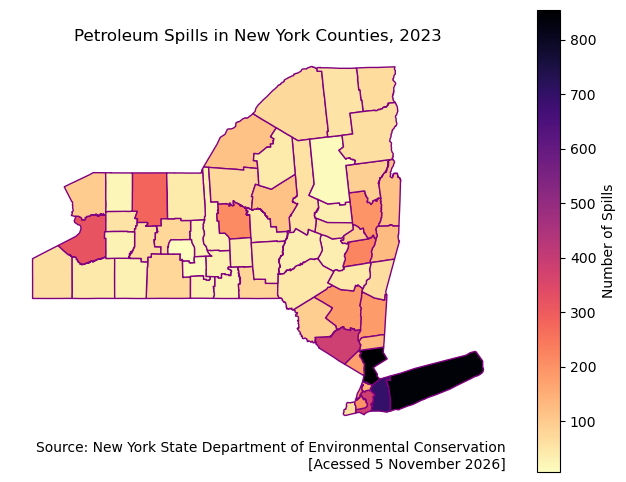

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

## 4. Import data 
In the next cell:

- Import the NY spills data as a variable named `spills`. 
- Import the US counties data as a variable named `counties`.

If you are using file paths to access the data, these should be constructed using the `os` package.

In [4]:
fp = os.path.join('data','Spill_Incidents_20261102.csv')
spills = pd.read_csv(fp)

fp = os.path.join('data','tl_2026_us_county', 'tl_2026_us_county.shp')
counties = gpd.read_file(fp)

<!-- BEGIN QUESTION -->

## 5. Prepare spills data

This section refers to the `spills` dataframe. 
Check the outputs carefully, they will give you information you will need to use in the next exercises.

### 5.A. Exploration

In the next cells:

a. Check the dataframe's head

b. Check the data types of the columns

c. Check the unique values in the `material_family` column

d. Check the unique values in the `county` column

e. Insert a markdown cell to explain what information you obtained from the preliminary exploration. Use complete sentences.

You can add any other cells for preliminary data exploration.

The spills data has a total of 20 columns and 574732 rows, where each row indicates a spill incident. There is a focus on the reporting the type of material that was spilled,as none of the values in the `Material Family` and `Material Name` columns are empty. There are some unexpected data types associated with some columns. For example, columns with dates have a data type of 'object.' Additionally, some numeric columns such as `Quantity` and `Recovered` have commas that are preventing the columns from having the correct data types. The `County` column indicates they consider Native American Reservations as distict counties. There are some values indicating a certain region in other states/countires for example : "Massachusetts - Region 4", "Canada - Region 6". 

In [5]:
#a. Check the dataframe's head
spills.head()

,Spill Number,Program Facility Name,Street 1,Street 2,Locality,County,ZIP Code,SWIS Code,DEC Region,Spill Date,Received Date,Contributing Factor,Waterbody,Source,Close Date,Material Name,Material Family,Quantity,Units,Recovered
0,107132,MH 864,RT 119/MILLWOOD RD,NaN,ELMSFORD,Westchester,NaN,6000,3,10/10/2001,10/10/2001,Unknown,NaN,Unknown,10/15/2001,unknown material,Other,10,Gallons,0
1,405586,BOWRY BAY,WATER POLL CONTROL,NaN,QUEENS,Queens,NaN,4101,2,08/21/2004,08/21/2004,Other,EAST RIVER,Unknown,09/17/2004,raw sewage,Other,0,NaN,0
2,405586,BOWRY BAY,WATER POLL CONTROL,NaN,QUEENS,Queens,NaN,4101,2,08/21/2004,08/21/2004,Other,EAST RIVER,Unknown,09/17/2004,raw sewage,Other,0,Pounds,0
3,204667,POLE 16091,GRACE AVE/BURKE AVE,NaN,BRONX,Bronx,NaN,301,2,08/02/2002,08/02/2002,Equipment Failure,NaN,Commercial/Industrial,10/28/2002,transformer oil,Petroleum,1,Gallons,0
4,210559,POLE ON,FERDALE LOMIS RD / RT 52,NaN,LIBERTY,Sullivan,NaN,5336,3,01/20/2003,01/20/2003,Traffic Accident,NaN,Commercial/Industrial,01/22/2003,transformer oil,Petroleum,6,Gallons,6


In [6]:
#b. Check the data types of the columns
spills.dtypes

Spill Number              int64
Program Facility Name    object
Street 1                 object
Street 2                 object
Locality                 object
County                   object
ZIP Code                 object
SWIS Code                 int64
DEC Region                int64
Spill Date               object
Received Date            object
Contributing Factor      object
Waterbody                object
Source                   object
Close Date               object
Material Name            object
Material Family          object
Quantity                 object
Units                    object
Recovered                object
dtype: object

In [7]:
#c. Check the unique values in the `material_family` column
spills['Material Family'].value_counts()

Material Family
Petroleum             485789
Other                  70882
Hazardous Material     17662
Oxygenates               399
Name: count, dtype: int64

In [8]:
#d. Check the unique values in the `county` column
spills['County'].value_counts()

County
Westchester                                57266
Suffolk                                    52944
Nassau                                     46355
Queens                                     30853
Erie                                       26190
                                           ...  
Vermont - Region 5 (R)                         1
Connecticut - Region 4                         1
Oil Springs Indian Reservation                 1
Canada - Region 5                              1
St. Regis Indian Reservation - Region 5        1
Name: count, Length: 87, dtype: int64

In [9]:
# Determine if the Recovered column has special character
spills[spills['Recovered'].str.contains(',')]

,Spill Number,Program Facility Name,Street 1,Street 2,Locality,County,ZIP Code,SWIS Code,DEC Region,Spill Date,Received Date,Contributing Factor,Waterbody,Source,Close Date,Material Name,Material Family,Quantity,Units,Recovered
231,906381,****DRILL**** AMERICAN SUGAR,1 FEDERAL ST,NaN,YONKERS,Westchester,NaN,6018,3,09/02/2009,09/02/2009,Equipment Failure,NaN,Commercial/Industrial,09/02/2009,#2 fuel oil,Petroleum,"4,000",Gallons,"2,800"
234,908968,****TEST**** DEC,625 BROADWAY TEST,NaN,ALBANY,Albany,NaN,101,4,11/10/2009,11/10/2009,Human Error,POSTENKILL CREEK,"Institutional, Educational, Gov., Other",11/12/2009,other - donut filling,Other,"1,000",Gallons,"1,000"
1128,1211553,101-19 158th Avenue,101-19 158th Avenue,NaN,Howard Beach,Queens,11414,4101,2,10/29/2012,11/13/2012,Storm,NaN,Private Dwelling,03/27/2013,#2 fuel oil,Petroleum,0,NaN,"1,200"
1993,1400712,11080 ROUTE 38,11080 ROUTE 38,NaN,CONQUEST,Cayuga,NaN,626,7,04/21/2014,04/21/2014,Traffic Accident,NaN,Commercial Vehicle,01/21/2015,fertilizers,Other,"23,000",Pounds,"22,900"
2221,1212249,114 Kensington Ave (Hurricane Sandy),114 Kensington Ave,NaN,Manhattan Bea,Kings,11235,2401,2,10/29/2012,11/16/2012,Storm,NaN,Private Dwelling,11/13/2012,#2 fuel oil,Petroleum,0,NaN,"1,100"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
573408,8808343,YOUNG DRUMS,555 RIVER ROAD,NaN,NORTH TONAWANDA,Niagara,NaN,3212,9,01/17/1989,01/18/1989,Abandoned Drums,NaN,Commercial/Industrial,07/12/1989,white caustic,Hazardous Material,"4,400",Gallons,"4,400"
574370,8709982,ZINC CORP. OF AMERICA,ZINC CORP. OF AMER.,NaN,FOWLER,St Lawrence,NaN,4538,6,02/25/1988,02/25/1988,Tank Failure,NONE,Commercial/Industrial,04/14/1988,unknown petroleum,Petroleum,"11,000",Gallons,"8,500"
574375,9009582,ZINC CORP. OF AMERICA,2500'LEVEL BALMAT MINE,NaN,FOWLER,St Lawrence,NaN,4538,6,12/04/1990,12/04/1990,Human Error,NONE,Commercial/Industrial,05/10/1991,#2 fuel oil,Petroleum,"2,500",Gallons,"2,500"
574438,8300526,ZITRO,1789 MONTAUK HIGHWAY,NaN,BELLPORT,Suffolk,NaN,5222,1,06/09/1983,06/09/1983,Tank Test Failure,NaN,Gasoline Station or other PBS Facility,03/23/1999,gasoline,Petroleum,0,Gallons,"2,922"


In [10]:
# Determine if the Quantity column has special character
spills[spills['Quantity'].str.contains(',')]

,Spill Number,Program Facility Name,Street 1,Street 2,Locality,County,ZIP Code,SWIS Code,DEC Region,Spill Date,Received Date,Contributing Factor,Waterbody,Source,Close Date,Material Name,Material Family,Quantity,Units,Recovered
87,1602923,#20,46 ELM ST OFF RT 11,NaN,CHAMPLAIN,Clinton,NaN,1028,5,06/23/2016,06/23/2016,Other,NaN,Commercial/Industrial,07/22/2016,unknown material,Other,"1,000",Gallons,0
231,906381,****DRILL**** AMERICAN SUGAR,1 FEDERAL ST,NaN,YONKERS,Westchester,NaN,6018,3,09/02/2009,09/02/2009,Equipment Failure,NaN,Commercial/Industrial,09/02/2009,#2 fuel oil,Petroleum,"4,000",Gallons,"2,800"
233,1002983,****TEST GOWANUS BAY****,29TH ST AND 2ND,NaN,BROOKLYN,Kings,NaN,2401,2,06/16/2010,06/16/2010,Equipment Failure,NaN,Commercial/Industrial,06/21/2010,#2 fuel oil,Petroleum,"26,964",Gallons,0
234,908968,****TEST**** DEC,625 BROADWAY TEST,NaN,ALBANY,Albany,NaN,101,4,11/10/2009,11/10/2009,Human Error,POSTENKILL CREEK,"Institutional, Educational, Gov., Other",11/12/2009,other - donut filling,Other,"1,000",Gallons,"1,000"
237,2105212,***DRILL*** EAST RIVER SUBSTATION,801 EAST 14TH ST,NaN,MANHATTAN,New York,NaN,3101,2,09/01/2021,09/01/2021,Equipment Failure,EAST RIVER,Gasoline Station or other PBS Facility,09/07/2021,#4 fuel oil,Petroleum,"2,100",Gallons,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
574541,8805196,ZOTOS INTERNATIONAL,FORGE AVENUE,NaN,GENEVA,Ontario,NaN,3530,8,09/12/1988,09/12/1988,Equipment Failure,NaN,Commercial/Industrial,09/12/1988,unknown petroleum,Petroleum,"100,000",Gallons,0
574567,1802752,ZUBER FARMS,NORTH BERGEN RD AND SOUTH HOLLEY RD,NaN,BYRON,Genesee,NaN,1926,8,06/11/2018,06/11/2018,Equipment Failure,NaN,Commercial/Industrial,06/27/2018,manure,Other,"7,000",Gallons,0
574627,8704228,ZUMPSTEIN INC,ROUTE 17,NaN,ALLEGANY,Cattaraugus,NaN,520,9,08/20/1987,08/21/1987,Traffic Accident,NaN,Commercial Vehicle,01/12/1988,salt,Other,"8,000",Pounds,"8,000"
574662,9009961,ZWACK RESIDENCE,6018 DOG HOLLOW RD,NaN,CUYLER,Cortland,NaN,1224,7,12/12/1990,12/12/1990,Tank Failure,NaN,Private Dwelling,08/15/1991,#2 fuel oil,Petroleum,"1,000",Gallons,0


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 5.B. Cleaning
a. Simplify column names as needed.

In [11]:
# Transform all column names into proper snake case
spills.columns = spills.columns.str.lower().str.replace(' ', '_')

# Inspect column names
spills.columns

Index(['spill_number', 'program_facility_name', 'street_1', 'street_2',
       'locality', 'county', 'zip_code', 'swis_code', 'dec_region',
       'spill_date', 'received_date', 'contributing_factor', 'waterbody',
       'source', 'close_date', 'material_name', 'material_family', 'quantity',
       'units', 'recovered'],
      dtype='object')

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Update column data types as needed.

In [12]:
# Update columns with dates (spill_date, close_date, received_date) into dates

# Create list of columns that need to be transformed into dates
date_columns = ['spill_date', 'close_date', 'received_date']
# Create a look to transform columns 
for column in date_columns:
    spills[column] = pd.to_datetime(spills[column])
    assert pd.api.types.is_datetime64_any_dtype(spills[column])

# Remove commas and transform column into numeric values (decimals)
spills['quantity'] = spills['quantity'].str.replace(',', '').astype('float64')
spills['recovered'] = spills['recovered'].str.replace(',', '').astype('float64')


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 5.C. Data selection

a. Select data about petroleum spills that took place between January 1 and December 31, 2023 (including both dates). Store it in a variable named `petr_23`. The data selection should occur in a single line. You may add cells as needed.

In [13]:
# Filter for petroleum spills in 2023
petr_23 = spills[(spills['spill_date'].between('2023-01-01', '2023-12-31')) & (spills['material_family'] == 'Petroleum')]
petr_23

,spill_number,program_facility_name,street_1,street_2,locality,county,zip_code,swis_code,dec_region,spill_date,received_date,contributing_factor,waterbody,source,close_date,material_name,material_family,quantity,units,recovered
70,2307439,#2 F/O IN GULLY (SMITH RESIDENCE),3666 MIDDLE ROAD,NaN,BURDETT,Schuyler,14818,4926,8,2023-12-08,2023-12-08,Traffic Accident,NaN,Tank Truck,2024-12-18,diesel,Petroleum,300.0,Gallons,0.0
220,2301892,*** TEST SPILL ***,*** TEST SPILL ***,NaN,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,2023-06-06,Tank Test Failure,NaN,Unknown,2023-07-12,diesel,Petroleum,0.0,NaN,0.0
221,2301892,*** TEST SPILL ***,*** TEST SPILL ***,NaN,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,2023-06-06,Tank Test Failure,NaN,Unknown,2023-07-12,#2 fuel oil,Petroleum,0.0,Gallons,0.0
222,2301892,*** TEST SPILL ***,*** TEST SPILL ***,NaN,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,2023-06-06,Tank Test Failure,NaN,Unknown,2023-07-12,gasoline,Petroleum,0.0,NaN,0.0
223,2301892,*** TEST SPILL ***,*** TEST SPILL ***,NaN,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,2023-06-06,Tank Test Failure,NaN,Unknown,2023-07-12,kerosene [#1 fuel oil] (on-site consumption),Petroleum,0.0,NaN,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
574319,2307849,ZIMINSKI RESIDENCE,1892 BEECH ST,NaN,WANTAGH,Nassau,11793,3020,1,2023-12-26,2023-12-26,Equipment Failure,NaN,Private Dwelling,2023-12-26,#2 fuel oil,Petroleum,0.5,Gallons,0.0
574331,2208304,ZIMMERMAN - UST,19 MOUNTAIN AVENUE,NaN,LARCHMONT,Westchester,NaN,6032,3,2023-01-10,2023-01-10,Equipment Failure,NaN,Private Dwelling,NaT,#2 fuel oil,Petroleum,0.0,NaN,0.0
574444,2307406,ZIZIC - UST,4 AUTUMN RIDGE RD,NaN,POUND RIDGE,Westchester,NaN,6046,3,2023-12-07,2023-12-07,Equipment Failure,NaN,Private Dwelling,2023-12-19,#2 fuel oil,Petroleum,0.0,NaN,0.0
574624,2301301,ZULTOWSKY - UST,514 PELHAM MANOR RD,NaN,PELHAM,Westchester,NaN,6044,3,2023-05-16,2023-05-16,Equipment Failure,NaN,Private Dwelling,2023-07-11,#2 fuel oil,Petroleum,0.0,NaN,0.0


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Use `print()` and f-strings to print a message verifying that `petr_23` only has data for 2023 and from January through December.
HINT: if you converted the `spill_date` column to datetime, you can use `petr_23['spill_date'].dt.year.unique()`.

In [14]:
print(f"Year(s) in petr_23: {petr_23['spill_date'].dt.year.unique()}")

Year(s) in petr_23: [2023]


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

c. Write tests using `assert` to verify that `petr_23` only has data for petroleum spills.

In [15]:
assert (petr_23['material_family'] == 'Petroleum').all()


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

d. Use `print()` and f-strings to print the number of rows in `petr_23` and the number of unique spills (use the `spill_number` column). Are these numbers the same? In the next markdown cell, explain why this might be the case. Use complete sentences. You may use additional cells to explore the data if needed.

In [16]:
print(f"Number of petr_23 rows: {petr_23.shape[0]}")
print(f"Number of unique spills: {petr_23['spill_number'].nunique()}")

Number of petr_23 rows: 8468
Number of unique spills: 8228


In [17]:
# Select the spill number and materials columns to identify the cause of mismatched number of rows
petr_23[['spill_number', 'material_family', 'material_name']]

,spill_number,material_family,material_name
70,2307439,Petroleum,diesel
220,2301892,Petroleum,diesel
221,2301892,Petroleum,#2 fuel oil
222,2301892,Petroleum,gasoline
223,2301892,Petroleum,kerosene [#1 fuel oil] (on-site consumption)
...,...,...,...
574319,2307849,Petroleum,#2 fuel oil
574331,2208304,Petroleum,#2 fuel oil
574444,2307406,Petroleum,#2 fuel oil
574624,2301301,Petroleum,#2 fuel oil


In the metadata, the authors of the dataset explain that there may be more than one column per spill number if there are multiple materials associated with that spill number. Although every row in the data represents a petroleum spill, (it is the material family), there are multiple derivatives of petroleum (gasoline, kerosene, diesel, etc.) that also infiltrated communities during the same spill incident. Thus, it is recorded as a new row in this dataset for every associated material, but with the same spill number. 

<!-- END QUESTION -->

### 5.D. Data aggregation

Create new dataframe named `spills_per_county` with the number of petroleum spills per county from January to December 2023.

As you found in exercise 5.C.d, a spill can appear in more than one row. Make sure you count each spill only once. HINT: `nunique()`.

The resulting `spills_per_county` dataframe must be as follows:

- Index: integer numbers starting from 0
- Two columns only.
- Column one: county names, column name = `county`
- Column two: number of petroleum spills per county in 2023, column name = `n_spills`

You may add cells if needed for your data wrangling.

In [18]:
# New dataframe with the number of petroleum spills per county from January to December 2023
spills_per_county = petr_23.groupby('county')['spill_number'].nunique().reset_index(name='n_spills')
spills_per_county 


,county,n_spills
0,Albany,224
1,Allegany,32
2,Bronx,152
3,Broome,80
4,Cattaraugus,45
...,...,...
61,Washington,115
62,Wayne,41
63,Westchester,855
64,Wyoming,27


In [19]:
grader.check("q5d")

q5d results: All test cases passed!

<!-- BEGIN QUESTION -->

## 6. Prepare counties data

This section refers to the `counties` geo-dataframe. 
Check the outputs carefully, they will give you context about the next exercises.

### 6.A. Exploration

In the next cells:

a. Check the geo-dataframe's head

b. Check the data types of the columns

c. Check the geo-dataframe's CRS

d. Plot the geo-dataframe

e. Use the next markdown cell to explain what information you obtained from the preliminary exploration. Use complete sentences.

You can add any other cells of preliminary data exploration.

From this exploration, I discovered that there is no column for state, only a name for the county. States are discernible by their internal state code system. These state codes are also considered strings. Most columns contain strings, only a few (land and water area, ALAND & AWATER) are considered to be numeric, and the geometry column contains polygons. Additionally, latitude and longitude columns (INTPTLAT INTPTLON) are considered strings and contain extra symbols and numbers (+ and 0s) in some cells. It contains county information for all of the United States and Canada (onshore and offshore). It's CRS is EPSG:4269 and is in degrees. 

In [20]:
# a
counties.head()

,STATEFP,COUNTYFP,COUNTYNS,GEOID,GEOIDFQ,NAME,NAMELSAD,LSAD,CLASSFP,MTFCC,CSAFP,CBSAFP,METDIVFP,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,12,009,00295749,12009,0500000US12009,Brevard,Brevard County,06,H1,G4020,None,37340,None,A,2628767922,1403935652,+28.2983112,-080.7003334,"POLYGON ((-80.98725 28.61300, -80.98674 28.613..."
1,06,055,00277292,06055,0500000US06055,Napa,Napa County,06,H1,G4020,488,34900,None,A,1947608455,104442639,+38.5073502,-122.3259960,"POLYGON ((-122.10363 38.51216, -122.10365 38.5..."
2,18,065,00450359,18065,0500000US18065,Henry,Henry County,06,H1,G4020,294,35220,None,A,1014957933,7652087,+39.9252934,-085.3991588,"POLYGON ((-85.31955 39.78736, -85.32016 39.787..."
3,35,029,00933057,35029,0500000US35029,Luna,Luna County,06,H1,G4020,None,19700,None,A,7679773747,433660,+32.1845231,-107.7471911,"POLYGON ((-108.22982 32.20878, -108.22981 32.2..."
4,10,001,00217271,10001,0500000US10001,Kent,Kent County,06,H1,G4020,428,20100,None,A,1517891100,549776927,+39.0970884,-075.5029819,"POLYGON ((-75.31622 39.24531, -75.31308 39.241..."


In [21]:
# b
counties.dtypes

STATEFP       object
COUNTYFP      object
COUNTYNS      object
GEOID         object
GEOIDFQ       object
NAME          object
NAMELSAD      object
LSAD          object
CLASSFP       object
MTFCC         object
CSAFP         object
CBSAFP        object
METDIVFP      object
FUNCSTAT      object
ALAND          int64
AWATER         int64
INTPTLAT      object
INTPTLON      object
geometry    geometry
dtype: object

In [22]:
# c
counties.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

<Axes: >

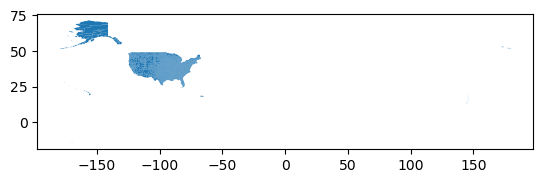

In [23]:
# d
counties.plot()

In [24]:
# Explore which columns have the most missing data
counties.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 3235 entries, 0 to 3234
Data columns (total 19 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   STATEFP   3235 non-null   object  
 1   COUNTYFP  3235 non-null   object  
 2   COUNTYNS  3235 non-null   object  
 3   GEOID     3235 non-null   object  
 4   GEOIDFQ   3235 non-null   object  
 5   NAME      3235 non-null   object  
 6   NAMELSAD  3235 non-null   object  
 7   LSAD      3235 non-null   object  
 8   CLASSFP   3235 non-null   object  
 9   MTFCC     3235 non-null   object  
 10  CSAFP     1341 non-null   object  
 11  CBSAFP    1915 non-null   object  
 12  METDIVFP  139 non-null    object  
 13  FUNCSTAT  3235 non-null   object  
 14  ALAND     3235 non-null   int64   
 15  AWATER    3235 non-null   int64   
 16  INTPTLAT  3235 non-null   object  
 17  INTPTLON  3235 non-null   object  
 18  geometry  3235 non-null   geometry
dtypes: geometry(1), int64(2), object(16)
mem

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 6.B. Cleaning

Simplify column names as needed.

In [25]:
# Column names seem reasonable, just need to make them lowercase
counties.columns = counties.columns.str.lower()
counties

,statefp,countyfp,countyns,geoid,geoidfq,name,namelsad,lsad,classfp,mtfcc,csafp,cbsafp,metdivfp,funcstat,aland,awater,intptlat,intptlon,geometry
0,12,009,00295749,12009,0500000US12009,Brevard,Brevard County,06,H1,G4020,None,37340,None,A,2628767922,1403935652,+28.2983112,-080.7003334,"POLYGON ((-80.98725 28.61300, -80.98674 28.613..."
1,06,055,00277292,06055,0500000US06055,Napa,Napa County,06,H1,G4020,488,34900,None,A,1947608455,104442639,+38.5073502,-122.3259960,"POLYGON ((-122.10363 38.51216, -122.10365 38.5..."
2,18,065,00450359,18065,0500000US18065,Henry,Henry County,06,H1,G4020,294,35220,None,A,1014957933,7652087,+39.9252934,-085.3991588,"POLYGON ((-85.31955 39.78736, -85.32016 39.787..."
3,35,029,00933057,35029,0500000US35029,Luna,Luna County,06,H1,G4020,None,19700,None,A,7679773747,433660,+32.1845231,-107.7471911,"POLYGON ((-108.22982 32.20878, -108.22981 32.2..."
4,10,001,00217271,10001,0500000US10001,Kent,Kent County,06,H1,G4020,428,20100,None,A,1517891100,549776927,+39.0970884,-075.5029819,"POLYGON ((-75.31622 39.24531, -75.31308 39.241..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3230,56,015,01605073,56015,0500000US56015,Goshen,Goshen County,06,H1,G4020,None,None,None,A,5764310957,16969719,+42.0894553,-104.3535403,"POLYGON ((-104.65564 42.60947, -104.65074 42.6..."
3231,55,107,01581114,55107,0500000US55107,Rusk,Rusk County,06,H1,G4020,None,None,None,A,2365981756,44924199,+45.4727342,-091.1367443,"POLYGON ((-91.04889 45.29201, -91.04909 45.292..."
3232,21,079,00516886,21079,0500000US21079,Garrard,Garrard County,06,H1,G4020,None,None,None,A,595502296,10414783,+37.6301619,-084.5458557,"POLYGON ((-84.74545 37.71562, -84.74501 37.716..."
3233,19,177,00465277,19177,0500000US19177,Van Buren,Van Buren County,06,H1,G4020,None,None,None,A,1255605672,14880500,+40.7541168,-091.9529430,"POLYGON ((-92.17907 40.89972, -92.17704 40.899..."


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 6.C. Data selection

Select all the counties for the state of New York in a new variable `ny_counties` and plot them (you may need to look at the metadata).

In [26]:
#  The state code for NY is 36
ny_counties = counties[counties['statefp'] == '36']
ny_counties.head()


,statefp,countyfp,countyns,geoid,geoidfq,name,namelsad,lsad,classfp,mtfcc,csafp,cbsafp,metdivfp,funcstat,aland,awater,intptlat,intptlon,geometry
258,36,029,00974113,36029,0500000US36029,Erie,Erie County,06,H1,G4020,160,15380,None,A,2700743371,476876406,+42.7527590,-078.7781922,"POLYGON ((-78.77760 42.46188, -78.77756 42.461..."
259,36,063,00974130,36063,0500000US36063,Niagara,Niagara County,06,H1,G4020,160,15380,None,A,1352876142,1598772310,+43.2726719,-078.8129431,"POLYGON ((-78.49165 43.08396, -78.49179 43.084..."
338,36,045,00974121,36045,0500000US36045,Jefferson,Jefferson County,06,H1,G4020,None,48060,None,A,3283928401,1524534721,+43.9963890,-076.0529678,"POLYGON ((-75.90417 43.69796, -75.90437 43.697..."
352,36,101,00974148,36101,0500000US36101,Steuben,Steuben County,06,H1,G4020,236,18500,None,A,3601403364,35034920,+42.2667252,-077.3855253,"POLYGON ((-77.08327 42.00002, -77.09391 41.999..."
492,36,099,00974147,36099,0500000US36099,Seneca,Seneca County,06,H1,G4020,464,42900,None,A,838377561,172813845,+42.7822943,-076.8270880,"POLYGON ((-76.96393 43.01284, -76.96393 43.012..."


Text(0.5, 1.0, 'New York Counties')

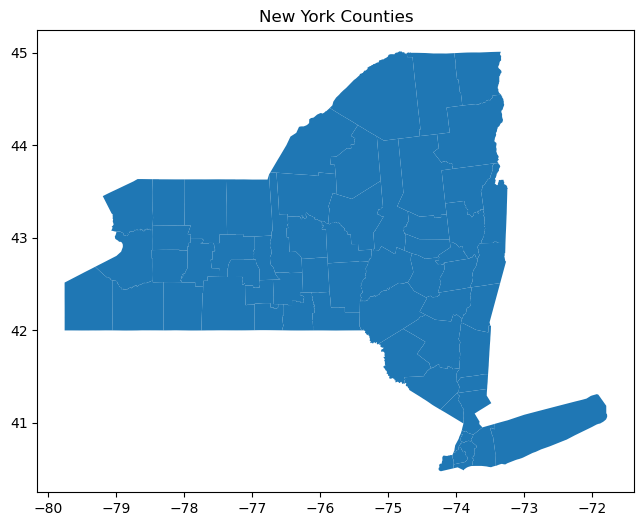

In [27]:
fig, ax = plt.subplots(figsize=(8,6))

ny_counties.plot(ax = ax)

ax.set_title('New York Counties')

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 7 Merging

The goal of this section is to create a single dataframe with the number of spills per county and the corresponding geometries for each county.

### 7.A. Explore data

In the next cells:

a. Print the names of counties in `ny_counties`, without repetition.


In [28]:
# Has 62 unique county names out of a series of 258 
ny_counties_unique = ny_counties['name'].unique()
print(ny_counties_unique)

['Erie' 'Niagara' 'Jefferson' 'Steuben' 'Seneca' 'Rensselaer' 'Albany'
 'Saratoga' 'Schoharie' 'Schenectady' 'Ulster' 'Dutchess' 'Orange'
 'Columbia' 'Tompkins' 'Tioga' 'Broome' 'Cayuga' 'Genesee' 'Onondaga'
 'Oswego' 'Madison' 'Livingston' 'Monroe' 'Ontario' 'Orleans' 'Wayne'
 'Chautauqua' 'Sullivan' 'Chemung' 'Cattaraugus' 'Fulton' 'Montgomery'
 'Cortland' 'Warren' 'Washington' 'Otsego' 'Queens' 'Bronx' 'Nassau'
 'Westchester' 'Richmond' 'Kings' 'Suffolk' 'Rockland' 'New York' 'Putnam'
 'Clinton' 'St. Lawrence' 'Herkimer' 'Oneida' 'Yates' 'Greene' 'Schuyler'
 'Delaware' 'Hamilton' 'Lewis' 'Allegany' 'Chenango' 'Wyoming' 'Franklin'
 'Essex']


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Print the names of counties in `spills_per_county`, without repetition. Examine the differences in the outputs.

In [29]:
# Has 66 unique county names
spills_per_county_unique = spills_per_county['county'].unique()
print(spills_per_county_unique)

['Albany' 'Allegany' 'Bronx' 'Broome' 'Cattaraugus' 'Cayuga' 'Chautauqua'
 'Chemung' 'Chenango' 'Clinton' 'Columbia' 'Cortland' 'Delaware'
 'Dutchess' 'Erie' 'Essex' 'Franklin' 'Fulton' 'Genesee' 'Greene'
 'Hamilton' 'Herkimer' 'Jefferson' 'Kings' 'Lewis' 'Livingston' 'Madison'
 'Monroe' 'Montgomery' 'Nassau' 'New Jersey - Region 2' 'New York'
 'Niagara' 'Oneida' 'Onondaga' 'Onondaga Indian Reservation' 'Ontario'
 'Orange' 'Orleans' 'Oswego' 'Otsego' 'Pennsylvania - Region 3' 'Putnam'
 'Queens' 'Rensselaer' 'Richmond' 'Rockland' 'Saratoga' 'Schenectady'
 'Schoharie' 'Schuyler' 'Seneca' 'St Lawrence' 'Steuben' 'Suffolk'
 'Sullivan' 'Tioga' 'Tompkins' 'Tuscarora Indian Reservation' 'Ulster'
 'Warren' 'Washington' 'Wayne' 'Westchester' 'Wyoming' 'Yates']


<!-- END QUESTION -->



c. Which are the county names that are in `spills_per_county`, but not in `ny_counties`? Your answer should be a list of strings
HINT: You can use the `numpy` function [`setdiff1d()`](https://numpy.org/doc/stable/reference/generated/numpy.setdiff1d.html), pay attention to the example in the documentation. Store your answer in the `diff_names` variable. 


In [30]:
diff_names_spills = np.setdiff1d(spills_per_county_unique, ny_counties_unique, assume_unique=True)
diff_names_spills


array(['New Jersey - Region 2', 'Onondaga Indian Reservation',
       'Pennsylvania - Region 3', 'St Lawrence',
       'Tuscarora Indian Reservation'], dtype=object)

In [31]:
grader.check("7Ac")

7Ac results: All test cases passed!

d. Which are the county names that are in `ny_counties`, but not in `spills_per_county`? Your answer should be a list of a string/strings.


In [32]:
diff_names_ny = np.setdiff1d(ny_counties_unique,spills_per_county_unique, assume_unique=True)
diff_names_ny

array(['St. Lawrence'], dtype=object)

In [33]:
grader.check("7Ad")

7Ad results: All test cases passed!

e. What is the number of spills in 'Tuscarora Indian Reservation' and in 'Onondaga Indian Reservation'?


In [34]:
# e. 
spills_per_county[(spills_per_county['county'] == 'Tuscarora Indian Reservation') | (spills_per_county['county'] == 'Onondaga Indian Reservation')]

,county,n_spills
35,Onondaga Indian Reservation,1
58,Tuscarora Indian Reservation,2


### 7.B. Data updates

In the next cell, update 'St Lawrence' to 'St. Lawrence' in the `spills_per_county` data frame. Verify the update was successful with an assert test. 


In [35]:
spills_per_county.loc[spills_per_county['county'] == 'St Lawrence', 'county'] = 'St. Lawrence'

In [36]:
spills_per_county

,county,n_spills
0,Albany,224
1,Allegany,32
2,Bronx,152
3,Broome,80
4,Cattaraugus,45
...,...,...
61,Washington,115
62,Wayne,41
63,Westchester,855
64,Wyoming,27


In [37]:
assert 'St. Lawrence' in spills_per_county['county'].values


### 7.C. Merge

In the following cells:

a. Use this cell to make any other updates needed for making an inner join of the `spills_per_county` and `ny_counties`. HINT: [`pd.merge`](https://pandas.pydata.org/pandas-docs/version/2.3/reference/api/pandas.merge.html)


In [38]:
# a 
# Update the 'name' column so that they have a column in common
ny_counties = ny_counties.rename(columns={'name':'county'}).copy()


In [39]:
# Merge the columns
pd.merge(ny_counties, spills_per_county, how = 'inner', on = 'county')

,statefp,countyfp,countyns,geoid,geoidfq,county,namelsad,lsad,classfp,mtfcc,csafp,cbsafp,metdivfp,funcstat,aland,awater,intptlat,intptlon,geometry,n_spills
0,36,029,00974113,36029,0500000US36029,Erie,Erie County,06,H1,G4020,160,15380,None,A,2700743371,476876406,+42.7527590,-078.7781922,"POLYGON ((-78.77760 42.46188, -78.77756 42.461...",320
1,36,063,00974130,36063,0500000US36063,Niagara,Niagara County,06,H1,G4020,160,15380,None,A,1352876142,1598772310,+43.2726719,-078.8129431,"POLYGON ((-78.49165 43.08396, -78.49179 43.084...",97
2,36,045,00974121,36045,0500000US36045,Jefferson,Jefferson County,06,H1,G4020,None,48060,None,A,3283928401,1524534721,+43.9963890,-076.0529678,"POLYGON ((-75.90417 43.69796, -75.90437 43.697...",114
3,36,101,00974148,36101,0500000US36101,Steuben,Steuben County,06,H1,G4020,236,18500,None,A,3601403364,35034920,+42.2667252,-077.3855253,"POLYGON ((-77.08327 42.00002, -77.09391 41.999...",77
4,36,099,00974147,36099,0500000US36099,Seneca,Seneca County,06,H1,G4020,464,42900,None,A,838377561,172813845,+42.7822943,-076.8270880,"POLYGON ((-76.96393 43.01284, -76.96393 43.012...",27
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57,36,003,00974100,36003,0500000US36003,Allegany,Allegany County,06,H1,G4020,None,None,None,A,2666410162,12989705,+42.2478532,-078.0261531,"POLYGON ((-78.04342 42.51846, -78.04326 42.518...",32
58,36,017,00974107,36017,0500000US36017,Chenango,Chenango County,06,H1,G4020,None,None,None,A,2314006867,13433903,+42.4780238,-075.6022407,"POLYGON ((-75.40346 42.50870, -75.40331 42.508...",44
59,36,121,00974158,36121,0500000US36121,Wyoming,Wyoming County,06,H1,G4020,None,None,None,A,1535086368,9085227,+42.7013652,-078.2285762,"POLYGON ((-77.95538 42.71354, -77.95537 42.713...",27
60,36,033,00974115,36033,0500000US36033,Franklin,Franklin County,06,H1,G4020,None,None,None,A,4219867377,176612003,+44.5943758,-074.3106700,"POLYGON ((-74.38487 44.11157, -74.38667 44.111...",55


b. Store the inner join of the `spills_per_county` and `ny_counties` dataframes in a new variable named `ny_spills`.


In [40]:
ny_spills = pd.merge(ny_counties, spills_per_county, how = 'inner', on = 'county')

<!-- BEGIN QUESTION -->

c. An inner join only keeps the rows whose `county` appears in both dataframes, and it does not warn you about the rows it drops. Which records from `spills_per_county` were dropped by the inner join, and how many spills did each one have? Add the cells you need to find the dropped records.

In [41]:
print(f"Counties county names in ny_counties: {len(ny_counties)}")
print(f"Counties in spills_per_county: {len(spills_per_county)}")
print(f"Counties county names in ny_spills: {len(ny_spills)}")

Counties county names in ny_counties: 62
Counties in spills_per_county: 66
Counties county names in ny_spills: 62


In [42]:
# Find the dropped records: counties in spills_per_county without a match in ny_counties
spills_per_county[~spills_per_county['county'].isin(ny_counties['county'])]

,county,n_spills
30,New Jersey - Region 2,7
35,Onondaga Indian Reservation,1
41,Pennsylvania - Region 3,1
58,Tuscarora Indian Reservation,2


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

d. Does dropping these records affect the map or the information we will report? Write your answer in the following markdown cell.

Dropping these records may not greatly affect the map. The merge dropped New Jersey - Region 2 and Pennsylvania - Region 3, which are not counties in New York so would therefore have no impact on the map nor the information we would report. However, in the case for the Native Reservations the census county data does not have geomertries this granular which does not make it possible to be mapped as is. Though these nations are within existing county designations, the Onondaga Indian Reservation is located in Onondaga county and Tuscarora is located in Niagra county. Dropping the soill records from the map would effectively underrepresent both of those counties. 

<!-- END QUESTION -->


From our previous exploration we know that Tuscarora Indian Reservation and Onondaga Indian Reservation will not be in the join. Tuscarora Indian Reservation is located within Niagara county and Onondaga Indian Reservation is located within Onondaga county. 

e. Since the reservations do not appear in the `ny_counties` dataframe, add the Tuscarora Indian Reservation spills to Niagara county and the Onondaga Indian Reservation spills to Onondaga county in `ny_spills`. We will add a note about this in our final map, and we will reflect on this choice in exercise 8.b. Add the cells you need to make this update **and** verify that the dataframe was updated.

In [ ]:
# Check how the Onondaga Reservation is named and number of spills
onondaga = spills_per_county[spills_per_county['county'].str.contains('Onondaga')]
onondaga

,county,n_spills
34,Onondaga,214
35,Onondaga Indian Reservation,1


In [ ]:
# Check how the Tuscarora Reservation is named and number of spills
tuscarora =spills_per_county[spills_per_county['county'].str.contains('Tuscarora')]
tuscarora

,county,n_spills
58,Tuscarora Indian Reservation,2


In [ ]:
# Check how the Niagara county is names and the number of spills
niagara =spills_per_county[spills_per_county['county'].str.contains('Niagara')]
niagara

,county,n_spills
32,Niagara,97


In [ ]:
# Replace the naming convention for one of the rows
spills_per_county['county'] = spills_per_county['county'].replace('Onondaga Indian Reservation', 'Onondaga')
spills_per_county['county'] = spills_per_county['county'].replace('Tuscarora Indian Reservation', 'Niagara')

# Recount the number of spills in each county 
spills_per_county = spills_per_county.groupby('county').sum()



In [47]:
# Merge again 
ny_spills = ny_counties.merge(spills_per_county, 
                                   how='inner',
                                   on='county')

print(f"Counties in ny_spills: {len(ny_spills)}")

Counties in ny_spills: 62


In [ ]:
# verify that ny_spills was updated
assert ny_spills.loc[ny_spills['county'] == 'Onondaga', 'n_spills'].item() == onondaga['n_spills'].sum()
assert ny_spills.loc[ny_spills['county'] == 'Niagara', 'n_spills'].item() == tuscarora['n_spills'].sum() + niagara['n_spills'].sum()

## 8. Map
a. Create a choropleth map of the number of petroleum spills per county in the state of New York in 2023. 
Your map should be polished and have (at least) the following updates:
- a legend indicating the number of spills
- an updated color map
- a title 
- no axis
- an annotation with the data source (New York State Department of Environmental Conservation) and date of access



Text(0.5, 1.0, 'Petroleum Spills in New York Counties, 2023')

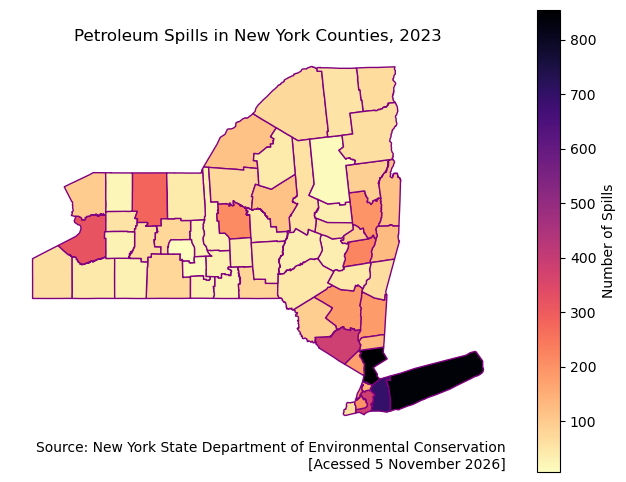

In [55]:
fig, ax = plt.subplots(figsize=(8,6))

ax.axis('off')

ny_spills.plot(ax = ax,
                      column='n_spills', #Indicates which column to color by
                      legend=True, 
                      cmap='magma_r',
                      edgecolor='purple',
                      legend_kwds={
                          "label":"Number of Spills"
                      })

ax.annotate(text = 'Source: New York State Department of Environmental Conservation\n[Acessed 5 November 2026]',
            xy=(1, -0.1),
            xycoords='axes fraction',
            horizontalalignment='right',
            verticalalignment='bottom')

ax.set_title('Petroleum Spills in New York Counties, 2023')

b. Write a description of how the map was created, including key takeaways. If you need to do additional data analysis to include relevant information from the data, you may include additional cells here.

In your description, also reflect on how we handled the spills reported in the Tuscarora and Onondaga Indian Reservations (exercise 7.C.e) in terms of data governance and the CARE Principles for Indigenous Data Governance from Task 1.

The chloropleth map was created using spills incident reports in New York State from 1990-2026. The data was provided by New York State Department of Environmental Conservation and every spill incident had an associated county and the material family (e.g. petroleum, hazardous etc.) of the substance that was spilled into the county. Column in the data were not ideal for working with and were updated into proprt snake case. Data had some inconsistencies in the data typed and were updates. After data cleaning, data was filtered for substances in the petroleum material family for 2023 (Januart 1 - December 31, 2023). Then, the number of spills that occurred in each county were counted by grouping by the county name and summed by the spill number as to avoid double counting. 

County data came from the US Census Bureau and contained census data from the US and Canada. Thus, counties data was filtered for New York using the code number 36 in the `statefp` column. 
This is what contains the geometry information (polygons).


Information in the `spills` data frame were more granular as data was collected solely for New York state. This gave the creators of the data set the liberty to be more specific about indicating where the spills occurred. This made it so that the data included Indian Reservations as their own "counties". Unfortunately, the census data used in this analysis is not as granular so we merged the Native Reservations into nearby counties. Specifically, the Tuscarora Indian Reservation was merged into Niagara county and the Onondaga Indian Reservation was merged into Onondaga county. 


Then we merged the two data sets, `spills_per_county` and `ny_counties` to attach the number of spills in each county to the geometry of each county. The number of spills column that was added to the geometry data was used to fill the hue of each county's polygon. 


In terms of the CARE Principles, specifically collectice benefit, stuffing spills from Native reservations means that the burden that is on the reservation cannot be seen or acted on by the native communities themselves. On Authority to control, both Tuscarora and Onondaga are soverign nations, so merging them into the counties they are geographically located in imposes likely unwanted state power on them. Reflecting on this, it would be a compromise to make a note of which counties contain soverign nations and their associated spillss. 


## Complete workflow

Collect all the relevant code into the first blank cell of the notebook titled "COMPLETE WORKFLOW". This single cell will have the end-to-end workflow: from importing libraries and loading the data, to producing the choropleth map of the number of petroleum spills per county in the state of New York in 2023. The only output of this cell should be the choropleth map  you produced in the previous exercise. Further guidance on what to include in this final workflow is in the assignment rubric.